## 1 Importing Libraries

In [22]:
import gc
import json
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.backend.clear_session()
gc.collect()
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.10.0


## Data Preprocessing

### Training and Validation Image Preprocessing

In [23]:
train_dir = r"D:\All Study Stuff\python\tf-env\python\HPCA Crop\Plant_Disease_Dataset\train"
IMG_SIZE = (128, 128)
BATCH_SIZE = 8

training_set = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

validation_set = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = training_set.class_names
num_classes = len(class_names)
print("Class Mapping:", list(enumerate(class_names)))

Found 2660 files belonging to 5 classes.
Using 2128 files for training.
Found 2660 files belonging to 5 classes.
Using 532 files for validation.
Class Mapping: [(0, 'Apple___Apple_scab'), (1, 'Apple___Black_rot'), (2, 'Apple___Cedar_apple_rust'), (3, 'Apple___healthy'), (4, 'Blotch_Apple')]


In [24]:
import os

train_dir = r"D:\All Study Stuff\python\tf-env\python\HPCA Crop\Plant_Disease_Dataset\train"
folders = [f for f in sorted(os.listdir(train_dir)) if os.path.isdir(os.path.join(train_dir, f))]

for idx, cls in enumerate(folders):
    print(f"Index {idx} ({cls}): {len(os.listdir(os.path.join(train_dir, cls)))} images")

Index 0 (Apple___Apple_scab): 376 images
Index 1 (Apple___Black_rot): 335 images
Index 2 (Apple___Cedar_apple_rust): 282 images
Index 3 (Apple___healthy): 480 images
Index 4 (Blotch_Apple): 1187 images


In [ ]:
# test Folder Counts
test_dir = r"D:\All Study Stuff\python\tf-env\python\HPCA Crop\Plant_Disease_Dataset\test"
test_folders = [f for f in sorted(os.listdir(test_dir)) if os.path.isdir(os.path.join(test_dir, f))]

for idx, cls in enumerate(test_folders):
    print(f"Test Index {idx} ({cls}): {len(os.listdir(os.path.join(test_dir, cls)))} images")

Test Index 0 (Apple___Apple_scab): 80 images
Test Index 1 (Apple___Black_rot): 61 images
Test Index 2 (Apple___Cedar_apple_rust): 44 images
Test Index 3 (Apple___healthy): 121 images
Test Index 4 (Blotch_Apple): 194 images


In [26]:
# Step 3: Define Data Augmentation Layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.15),
], name="data_augmentation")

### Step 4: Load Pretrained MobileNetV2 Backbone (Frozen)

In [27]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

### Step 5: Assemble the 5-Class Classification Model

In [28]:
inputs = tf.keras.Input(shape=(128, 128, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 128, 128, 3)]     0         
                                                                 
 data_augmentation (Sequenti  (None, 128, 128, 3)      0         
 al)                                                             
                                                                 
 tf.math.truediv (TFOpLambda  (None, 128, 128, 3)      0         
 )                                                               
                                                                 
 tf.math.subtract (TFOpLambd  (None, 128, 128, 3)      0         
 a)                                                              
                                                                 
 mobilenetv2_1.00_128 (Funct  (None, 4, 4, 1280)       2257984   
 ional)                                                      

In [29]:
for x,y in training_set:
    print(x,x.shape)
    print(y,y.shape)
    break

tf.Tensor(
[[[[100.79785  110.4375    70.71875 ]
   [101.       108.393555  68.78711 ]
   [102.40625  109.8125    63.760742]
   ...
   [127.583984 131.59473   47.021484]
   [127.36914  130.93164   48.65039 ]
   [128.24805  130.9668    50.575195]]

  [[101.125    111.518555  71.799805]
   [101.84375  109.975586  70.975586]
   [103.75098  111.15723   66.71875 ]
   ...
   [130.87598  133.03223   56.688477]
   [132.26758  132.58008   59.79883 ]
   [132.75586  131.61816   61.84961 ]]

  [[102.8125   114.34375   73.01074 ]
   [103.31348  113.7832    72.      ]
   [104.16504  114.8125    70.24121 ]
   ...
   [131.94629  129.59375   64.57129 ]
   [127.05469  124.930664  61.208008]
   [120.12207  119.35156   55.788086]]

  ...

  [[254.70801  255.       254.70801 ]
   [255.       255.       255.      ]
   [255.       255.       255.      ]
   ...
   [255.       255.       255.      ]
   [255.       255.       255.      ]
   [255.       255.       255.      ]]

  [[255.       255.       255.    

### Step 6A: Phase 1 — Compile & Train Classifier Head (5 Epochs)

In [30]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_1 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=5
)

Epoch 1/5
266/266 [==============================] - 165s 474ms/step - loss: 0.9080 - accuracy: 0.6852 - val_loss: 0.5017 - val_accuracy: 0.8402
Epoch 2/5
266/266 [==============================] - 91s 344ms/step - loss: 0.4824 - accuracy: 0.8271 - val_loss: 0.4339 - val_accuracy: 0.8515
Epoch 3/5
266/266 [==============================] - 101s 381ms/step - loss: 0.3899 - accuracy: 0.8628 - val_loss: 0.3805 - val_accuracy: 0.8816
Epoch 4/5
266/266 [==============================] - 147s 548ms/step - loss: 0.3524 - accuracy: 0.8764 - val_loss: 0.3839 - val_accuracy: 0.8759
Epoch 5/5
266/266 [==============================] - 82s 303ms/step - loss: 0.3259 - accuracy: 0.8764 - val_loss: 0.3389 - val_accuracy: 0.8966


### Step 6B: Phase 2 — Fine-Tune Top 30 Layers (8 Epochs)

In [31]:
# Step 6B (Updated with Class Weights to fix Blotch_Apple recall)
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

class_weights = {
    0: 1.2,  # Apple___Apple_scab
    1: 0.9,  # Apple___Black_rot
    2: 1.0,  # Apple___Cedar_apple_rust
    3: 1.0,  # Apple___healthy
    4: 1.8   # Blotch_Apple
}

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_2 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=8,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/8
266/266 [==============================] - 180s 544ms/step - loss: 0.4365 - accuracy: 0.8656 - val_loss: 0.3409 - val_accuracy: 0.8910
Epoch 2/8
266/266 [==============================] - 182s 685ms/step - loss: 0.3390 - accuracy: 0.8905 - val_loss: 0.2902 - val_accuracy: 0.8910
Epoch 3/8
266/266 [==============================] - 171s 643ms/step - loss: 0.2352 - accuracy: 0.9201 - val_loss: 0.1957 - val_accuracy: 0.9211
Epoch 4/8
266/266 [==============================] - 111s 413ms/step - loss: 0.2090 - accuracy: 0.9272 - val_loss: 0.2360 - val_accuracy: 0.9211
Epoch 5/8
266/266 [==============================] - 100s 373ms/step - loss: 0.1964 - accuracy: 0.9290 - val_loss: 0.1761 - val_accuracy: 0.9229
Epoch 6/8
266/266 [==============================] - 114s 428ms/step - loss: 0.1625 - accuracy: 0.9398 - val_loss: 0.2035 - val_accuracy: 0.9267
Epoch 7/8
266/266 [==============================] - 94s 351ms/step - loss: 0.1498 - accuracy: 0.9413 - val_loss: 0.2739 - val_acc

### Step 7: Evaluate on Training & Validation Sets

In [32]:
train_loss, train_acc = model.evaluate(training_set)
print(f"Training Loss: {train_loss:.4f} | Training Accuracy: {train_acc:.4f}")

val_loss, val_acc = model.evaluate(validation_set)
print(f"Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.4f}")

266/266 [==============================] - 92s 342ms/step - loss: 0.1115 - accuracy: 0.9511
Training Loss: 0.1115 | Training Accuracy: 0.9511
67/67 [==============================] - 20s 300ms/step - loss: 0.1761 - accuracy: 0.9229
Validation Loss: 0.1761 | Validation Accuracy: 0.9229


### Step 8: Save Upgraded Model & Combined Training History

In [33]:
model.save("apple_disease_model_v2.keras")
print("Saved apple_disease_model_v2.keras successfully!")

combined_history = {
    "accuracy": history_1.history["accuracy"] + history_2.history["accuracy"],
    "val_accuracy": history_1.history["val_accuracy"] + history_2.history["val_accuracy"],
    "loss": history_1.history["loss"] + history_2.history["loss"],
    "val_loss": history_1.history["val_loss"] + history_2.history["val_loss"],
}

with open("training_hist_v2.json", "w") as f:
    json.dump(combined_history, f)

Saved apple_disease_model_v2.keras successfully!


### Step 9: Plot Combined Accuracy Curve (Phase 1 + Phase 2)

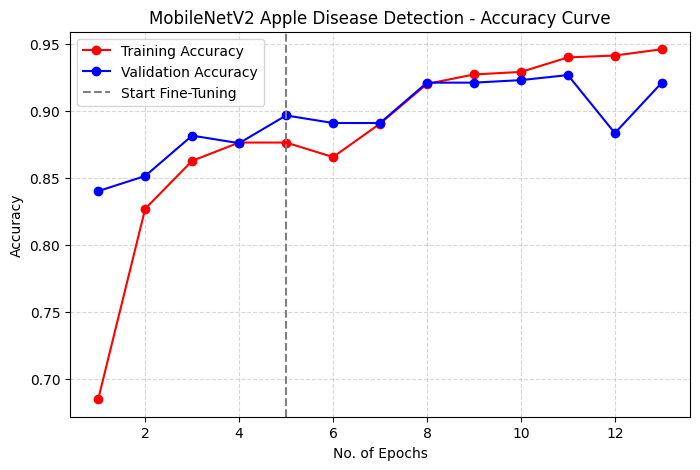

In [34]:
acc = combined_history["accuracy"]
val_acc = combined_history["val_accuracy"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, acc, color="red", marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_acc, color="blue", marker="o", label="Validation Accuracy")
plt.axvline(x=5, color="gray", linestyle="--", label="Start Fine-Tuning")
plt.xlabel("No. of Epochs")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Apple Disease Detection - Accuracy Curve")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Step 10: Test on Unseen test Folder & Plot Confusion Matrix

Found 500 files belonging to 5 classes.
63/63 [==============================] - 34s 446ms/step
                          precision    recall  f1-score   support

      Apple___Apple_scab       0.42      0.88      0.57        80
       Apple___Black_rot       0.41      0.77      0.53        61
Apple___Cedar_apple_rust       1.00      0.91      0.95        44
         Apple___healthy       0.93      0.93      0.93       121
            Blotch_Apple       0.95      0.28      0.44       194

                accuracy                           0.65       500
               macro avg       0.74      0.75      0.68       500
            weighted avg       0.80      0.65      0.63       500



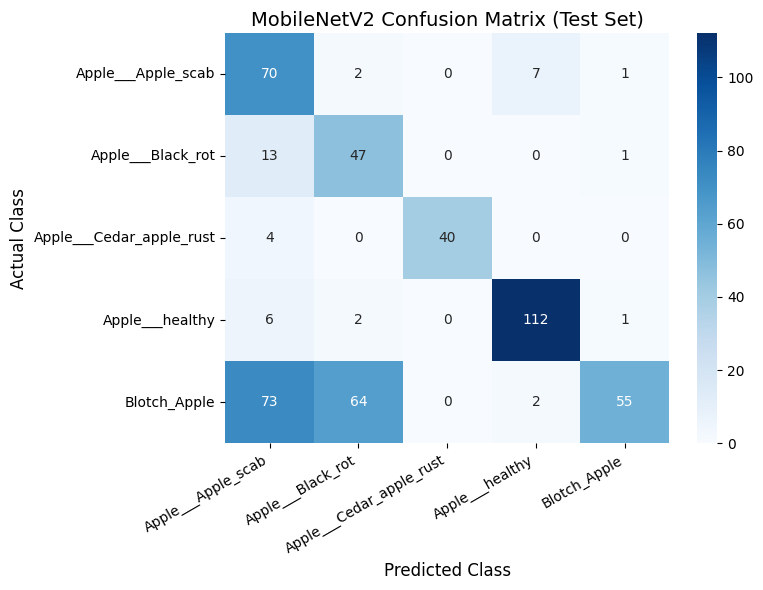

: 

In [ ]:
test_dir = r"D:\All Study Stuff\python\tf-env\python\HPCA Crop\Plant_Disease_Dataset\test"

test_set = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    batch_size=8,
    image_size=(128, 128),
    shuffle=False
)

y_pred = model.predict(test_set)
predicted_categories = tf.argmax(y_pred, axis=1)

true_categories = tf.concat([y for x, y in test_set], axis=0)
Y_true = tf.argmax(true_categories, axis=0 if len(true_categories.shape) == 1 else 1)

print(classification_report(Y_true, predicted_categories, target_names=class_names))

cm = confusion_matrix(Y_true, predicted_categories)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.title("MobileNetV2 Confusion Matrix (Test Set)", fontsize=14)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()